# 🚀 03 - Pipeline 2: Dual-Channel Word + Character TF-IDF
### Đề tài: AI-Generated Text Detection Using Machine Learning & NLP with Chrome Extension

---
## 🎯 Vai trò Chiến lược của Pipeline 2:
> **ỨNG VIÊN ƯU TIÊN SỐ 1 ĐỂ TRIỂN KHAI (DEPLOY) LÊN CHROME EXTENSION**  
> Mô hình kết hợp Word + Char TF-IDF sở hữu ưu điểm vượt trội:
> - **Siêu nhẹ & Tốc độ suy luận cực cao:** Latency chỉ khoảng $10 - 20\text{ ms}$, tiêu thụ cực ít RAM (vài chục MB).
> - **Khắc phục triệt để nhược điểm của Word TF-IDF:** Không bị "học vẹt" theo chủ đề bài viết; bắt trọn các đặc trưng hình thái vi mô (hậu tố từ dài của AI) và nhịp điệu ngắt nghỉ dấu câu.
> - **Không cần máy chủ GPU đắt đỏ:** Hoàn toàn chạy mượt mà trên CPU của Cloud VPS hoặc Server rẻ tiền.

```
                    ┌─────────────────────────────────────────────────────────┐
                    │               RAW TEXT (VĂN BẢN ĐẦU VÀO)                │
                    └───────────────────────────┬─────────────────────────────┘
                                                │
                 ┌──────────────────────────────┴──────────────────────────────┐
                 ▼                                                             ▼
  ┌─────────────────────────────┐                               ┌─────────────────────────────┐
  │      KÊNH 1: WORD TF-IDF    │                               │     KÊNH 2: CHARACTER TF-IDF│
  ├─────────────────────────────┤                               ├─────────────────────────────┤
  │ • Lowercase, Stop words     │                               │ • Pre-filtering tối thiểu   │
  │ • Word n-grams (1, 2)       │                               │ • GIỮ NGUYÊN DẤU CÂU & HOA  │
  │ • Bắt từ vựng học thuật     │                               │ • Sliding Window (3–5 grams)│
  │   (additionally, essential) │                               │ • Bắt hậu tố, nhịp dấu câu  │
  └──────────────┬──────────────┘                               └──────────────┬──────────────┘
                 │                                                             │
                 └──────────────────────────────┬──────────────────────────────┘
                                                ▼
                                ┌─────────────────────────────┐
                                │   FEATURE FUSION (hstack)   │
                                │ Ma trận kết hợp V_word + char│
                                └──────────────┬──────────────┘
                                                ▼
                                ┌─────────────────────────────┐
                                │     LINEAR CLASSIFIERS      │
                                │ (Logistic Reg / Linear SVM) │
                                └─────────────────────────────┘
```


---
## 1. Thiết lập Môi trường & Thư viện


In [1]:
import os
import re
import time
import json
import unicodedata
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy.sparse import hstack, csr_matrix

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    roc_auc_score, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve
)

warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 115, 'font.size': 11})

RANDOM_STATE = 42

print("✅ Đã nạp thành công các thư viện cho Pipeline 2!")


✅ Đã nạp thành công các thư viện cho Pipeline 2!


---
## 2. Nạp Dữ Liệu từ `data/processed/`
Sử dụng chung tập Train (341,040 mẫu) và Val (73,095 mẫu) với Pipeline 1 để đảm bảo tính **đối đầu công bằng tuyệt đối**.


In [2]:
# Đường dẫn tới thư mục data/processed
possible_data_dirs = [
    Path("../data/processed"),
    Path("data/processed"),
    Path(r"D:\Project SamSung\AI-gen-text-detection\data\processed")
]
DATA_DIR = next((d for d in possible_data_dirs if d.exists()), None)

if DATA_DIR is None:
    raise FileNotFoundError("Không tìm thấy thư mục data/processed! Hãy chạy data/processcing.py trước.")

print(f"📁 Thư mục dữ liệu: {DATA_DIR.resolve()}")

t0 = time.time()
train_df = pd.read_csv(DATA_DIR / "train.csv")
val_df = pd.read_csv(DATA_DIR / "val.csv")

print(f"✅ Đã nạp Train ({len(train_df):,} mẫu) và Val ({len(val_df):,} mẫu) trong {time.time() - t0:.2f}s.")

# TÙY CHỌN: Chạy FULL hoặc Subsample để benchmark nhanh
SAMPLE_LIMIT = None

if SAMPLE_LIMIT is not None and SAMPLE_LIMIT < len(train_df):
    train_df = train_df.sample(n=SAMPLE_LIMIT, random_state=RANDOM_STATE).reset_index(drop=True)
    val_sample = int(SAMPLE_LIMIT * 0.2)
    val_df = val_df.sample(n=val_sample, random_state=RANDOM_STATE).reset_index(drop=True)
    print(f"⚠️ Chế độ chạy nhanh: Train={len(train_df):,} | Val={len(val_df):,}")

X_train_raw = train_df['text']
y_train = train_df['target'].to_numpy()

X_val_raw = val_df['text']
y_val = val_df['target'].to_numpy()

print(f"Phân bố nhãn Train: Human={np.sum(y_train==0):,} ({np.mean(y_train==0):.1%}) | AI={np.sum(y_train==1):,} ({np.mean(y_train==1):.1%})")
print(f"Phân bố nhãn Val:   Human={np.sum(y_val==0):,} ({np.mean(y_val==0):.1%}) | AI={np.sum(y_val==1):,} ({np.mean(y_val==1):.1%})")


📁 Thư mục dữ liệu: D:\Project SamSung\AI-gen-text-detection\data\processed
✅ Đã nạp Train (341,040 mẫu) và Val (73,095 mẫu) trong 7.16s.
Phân bố nhãn Train: Human=214,050 (62.8%) | AI=126,990 (37.2%)
Phân bố nhãn Val:   Human=45,877 (62.8%) | AI=27,218 (37.2%)


---
## 3. Kênh 1: Word TF-IDF Vectorization
Trích xuất các unigram và bigram từ vựng, lọc stop words.


In [3]:
print("🔄 Đang xây dựng Kênh 1: Word TF-IDF Vectorizer...")
t0 = time.time()

word_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words='english',
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.90,
    sublinear_tf=True,
    max_features=40_000,
    norm='l2',
    dtype=np.float32
)

# Fit chỉ trên X_train!
X_train_word = word_vectorizer.fit_transform(X_train_raw)
X_val_word = word_vectorizer.transform(X_val_raw)

print(f"✅ Kênh 1 hoàn tất trong {time.time() - t0:.2f}s | Vocabulary: {len(word_vectorizer.vocabulary_):,} words")
print(f"📐 X_train_word shape: {X_train_word.shape}")


🔄 Đang xây dựng Kênh 1: Word TF-IDF Vectorizer...
✅ Kênh 1 hoàn tất trong 106.23s | Vocabulary: 40,000 words
📐 X_train_word shape: (341040, 40000)


---
## 4. Kênh 2: Character TF-IDF (Sliding Window & Pre-filtering Tối thiểu)

### 📌 Nguyên tắc Tiền xử lý mức Ký tự:
1. **Pre-filtering tối thiểu:**
   - **KHÔNG lowercase:** Giữ nguyên chữ hoa (để bắt thói quen viết hoa chuẩn mực của AI vs viết hoa tự do của người).
   - **KHÔNG strip dấu câu:** Giữ nguyên dấu phẩy, chấm, gạch ngang, chấm phẩy (để bắt nhịp điệu ngắt nghỉ).
   - **Chỉ chuẩn hóa Unicode NFC và khoảng trắng thừa:** Gộp nhiều space liên tiếp thành 1 space.
2. **Sliding Window N-grams với `analyzer='char_wb'` (within word boundaries):**
   - Ký tự được bọc bởi khoảng trắng ở 2 đầu trước khi trượt cửa sổ $k \in [3, 5]$:
   - Giúp phân biệt rõ:
     - **Tiền tố:** Bắt đầu bằng khoảng trắng (ví dụ: `" un"`, `" dis"`, `" re"`).
     - **Hậu tố:** Kết thúc bằng khoảng trắng (ví dụ: `"tion "`, `"ally "`, `"ment "`).
     - **Dấu câu dính liền từ:** Bắt thói quen ngắt nhịp (ví dụ: `", wh"`, `"— "`, `"; "`).


In [4]:
# Hàm Pre-filtering tối thiểu cho Kênh Character
def minimal_char_preprocessor(text):
    if pd.isna(text):
        return ""
    # 1. Chuẩn hóa Unicode về dạng chuẩn NFC
    text = unicodedata.normalize('NFC', str(text))
    # 2. Chỉ gộp các khoảng trắng thừa liên tiếp thành 1 space, giữ nguyên chữ HOA và dấu câu!
    text = re.sub(r'\s+', ' ', text).strip()
    return text


# Minh họa cơ chế hoạt động của char_wb
sample_snippet = "AI! Crucial..."
demo_vec = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 4), preprocessor=minimal_char_preprocessor)
demo_vec.fit([sample_snippet])
print(f"Ví dụ văn bản: '{sample_snippet}'")
print(f"Các n-grams ký tự (char_wb 3-4) được trích xuất:")
print(demo_vec.get_feature_names_out().tolist()[:15])


Ví dụ văn bản: 'AI! Crucial...'
Các n-grams ký tự (char_wb 3-4) được trích xuất:
[' AI', ' AI!', ' Cr', ' Cru', '.. ', '...', '... ', 'AI!', 'AI! ', 'Cru', 'Cruc', 'I! ', 'al.', 'al..', 'cia']


In [5]:
print("🔄 Đang xây dựng Kênh 2: Character TF-IDF Vectorizer...")
t0 = time.time()

char_vectorizer = TfidfVectorizer(
    preprocessor=minimal_char_preprocessor,
    analyzer='char_wb',
    ngram_range=(3, 5),
    min_df=10,
    max_df=0.90,
    sublinear_tf=True,
    max_features=60_000,
    norm='l2',
    dtype=np.float32
)

# Fit chỉ trên X_train!
X_train_char = char_vectorizer.fit_transform(X_train_raw)
X_val_char = char_vectorizer.transform(X_val_raw)

print(f"✅ Kênh 2 hoàn tất trong {time.time() - t0:.2f}s | Vocabulary: {len(char_vectorizer.vocabulary_):,} char n-grams")
print(f"📐 X_train_char shape: {X_train_char.shape}")


🔄 Đang xây dựng Kênh 2: Character TF-IDF Vectorizer...
✅ Kênh 2 hoàn tất trong 541.40s | Vocabulary: 60,000 char n-grams
📐 X_train_char shape: (341040, 60000)


---
## 5. Ghép nối Không gian Đặc trưng (Feature Fusion via `hstack`)
Sử dụng `scipy.sparse.hstack` để ghép ma trận Word và Character thành một ma trận thưa tổng hợp duy nhất:
$$X_{\text{dual}} = [X_{\text{word}} \;\; X_{\text{char}}]$$


In [6]:
print("🔄 Đang ghép nối không gian đặc trưng Word + Character...")
t0 = time.time()

X_train_dual = hstack([X_train_word, X_train_char], format='csr')
X_val_dual = hstack([X_val_word, X_val_char], format='csr')

print(f"✅ Ghép nối hoàn tất trong {time.time() - t0:.2f}s!")
print(f"📐 Tổng số chiều đặc trưng kết hợp (V_dual): {X_train_dual.shape[1]:,} features")
print(f"📐 X_train_dual shape: {X_train_dual.shape} | Dung lượng: {X_train_dual.data.nbytes / 1e6:.1f} MB")
print(f"📐 X_val_dual shape:   {X_val_dual.shape} | Dung lượng: {X_val_dual.data.nbytes / 1e6:.1f} MB")


🔄 Đang ghép nối không gian đặc trưng Word + Character...
✅ Ghép nối hoàn tất trong 23.52s!
📐 Tổng số chiều đặc trưng kết hợp (V_dual): 100,000 features
📐 X_train_dual shape: (341040, 100000) | Dung lượng: 2737.3 MB
📐 X_val_dual shape:   (73095, 100000) | Dung lượng: 584.5 MB


---
## 6. Huấn luyện Đối đầu các Mô hình Tuyến tính
Huấn luyện 3 mô hình tuyến tính mạnh nhất với `n_jobs=-1`:
1. **SGDClassifier (Log Loss):** Siêu tốc, phù hợp với dữ liệu lớn hàng trăm ngàn chiều.
2. **Linear Support Vector Machine (LinearSVC):** Cực kỳ mạnh mẽ trong không gian phân loại văn bản số chiều lớn (100k chiều).
3. **Logistic Regression (L2):** Mô hình chuẩn mực, xác suất mượt mà.


In [7]:
def evaluate_model(model_name, y_true, y_pred, y_prob=None, train_time=0.0, latency_ms=0.0):
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average=None, labels=[0, 1])
    macro_f1 = (f1[0] + f1[1]) / 2.0
    
    roc_auc = roc_auc_score(y_true, y_prob) if y_prob is not None else 0.0
    pr_auc = average_precision_score(y_true, y_prob) if y_prob is not None else 0.0
    
    metrics = {
        'Model': model_name,
        'Accuracy': acc,
        'Macro-F1': macro_f1,
        'AI Precision': prec[1],
        'AI Recall': rec[1],
        'AI F1': f1[1],
        'Human F1': f1[0],
        'ROC-AUC': roc_auc,
        'PR-AUC': pr_auc,
        'Train Time (s)': round(train_time, 2),
        'Latency (ms/1k)': round(latency_ms, 2)
    }
    return metrics


models = {
    'SGDClassifier (Log Loss)': SGDClassifier(loss='log_loss', penalty='l2', alpha=1e-5, max_iter=1000, random_state=RANDOM_STATE, n_jobs=-1),
    'Linear SVM (LinearSVC)': LinearSVC(C=1.0, max_iter=2000, random_state=RANDOM_STATE),
    'Logistic Regression (L2)': LogisticRegression(C=2.5, max_iter=1000, solver='lbfgs', random_state=RANDOM_STATE, n_jobs=-1)
}

benchmark_results = []
trained_models = {}

print("🏋️‍♂️ BẮT ĐẦU HUẤN LUYỆN CÁC MÔ HÌNH PIPELINE 2:")
print("=" * 75)

for name, model in models.items():
    print(f"⏳ Đang huấn luyện: {name} ...", end=" ", flush=True)
    t_start = time.time()
    model.fit(X_train_dual, y_train)
    t_train = time.time() - t_start
    
    # Đo độ trễ suy luận trên 1,000 mẫu
    t_lat = time.time()
    sample_val = X_val_dual[:1000]
    _ = model.predict(sample_val)
    latency_ms = (time.time() - t_lat) * 1000.0
    
    # Dự đoán trên toàn bộ tập Validation
    y_pred = model.predict(X_val_dual)
    
    # Lấy xác suất
    if hasattr(model, 'predict_proba'):
        y_prob = model.predict_proba(X_val_dual)[:, 1]
    elif hasattr(model, 'decision_function'):
        scores = model.decision_function(X_val_dual)
        y_prob = 1.0 / (1.0 + np.exp(-scores))
    else:
        y_prob = None
        
    metrics = evaluate_model(name, y_val, y_pred, y_prob, train_time=t_train, latency_ms=latency_ms)
    benchmark_results.append(metrics)
    trained_models[name] = (model, y_pred, y_prob)
    
    print(f"Xong ({t_train:.1f}s) | Macro-F1: {metrics['Macro-F1']:.4f} | AI Recall: {metrics['AI Recall']:.4f} | Latency: {latency_ms:.1f}ms")

print("=" * 75)
print("🎉 Đã hoàn thành huấn luyện tất cả mô hình trong Pipeline 2!")


🏋️‍♂️ BẮT ĐẦU HUẤN LUYỆN CÁC MÔ HÌNH PIPELINE 2:
⏳ Đang huấn luyện: SGDClassifier (Log Loss) ... Xong (11.1s) | Macro-F1: 0.9963 | AI Recall: 0.9923 | Latency: 12.9ms
⏳ Đang huấn luyện: Linear SVM (LinearSVC) ... Xong (306.3s) | Macro-F1: 0.9996 | AI Recall: 0.9993 | Latency: 72.8ms
⏳ Đang huấn luyện: Logistic Regression (L2) ... Xong (31.3s) | Macro-F1: 0.9975 | AI Recall: 0.9953 | Latency: 9.9ms
🎉 Đã hoàn thành huấn luyện tất cả mô hình trong Pipeline 2!


---
## 7. Bảng Xếp Hạng Leaderboard & So sánh với Pipeline 1
Đánh giá xem việc bổ sung Kênh Ký tự (Character TF-IDF) giúp cải thiện chỉ số Macro-F1 và AI Recall như thế nào.


🏆 BẢNG XẾP HẠNG CÁC MÔ HÌNH PIPELINE 2 (DUAL-CHANNEL TF-IDF):


,Model,Accuracy,Macro-F1,AI Precision,AI Recall,AI F1,Human F1,ROC-AUC,PR-AUC,Train Time (s),Latency (ms/1k)
0,Linear SVM (LinearSVC),0.999617,0.999590,0.999706,0.999265,0.999486,0.999695,0.999997,0.999995,306.310000,72.820000
1,Logistic Regression (L2),0.997702,0.997540,0.998526,0.995297,0.996909,0.998171,0.999852,0.999804,31.340000,9.870000
2,SGDClassifier (Log Loss),0.996566,0.996322,0.998484,0.992285,0.995375,0.997269,0.999765,0.999687,11.110000,12.870000



🔥 SO SÁNH ĐỐI ĐẦU: PIPELINE 1 vs PIPELINE 2:


,Pipeline,Model,Macro-F1,AI Recall,AI Precision
0,Pipeline 1 (Chỉ Word TF-IDF),Linear SVM (LinearSVC),0.999297,0.998604,0.999632
1,Pipeline 2 (Word + Char TF-IDF),Linear SVM (LinearSVC),0.999590,0.999265,0.999706


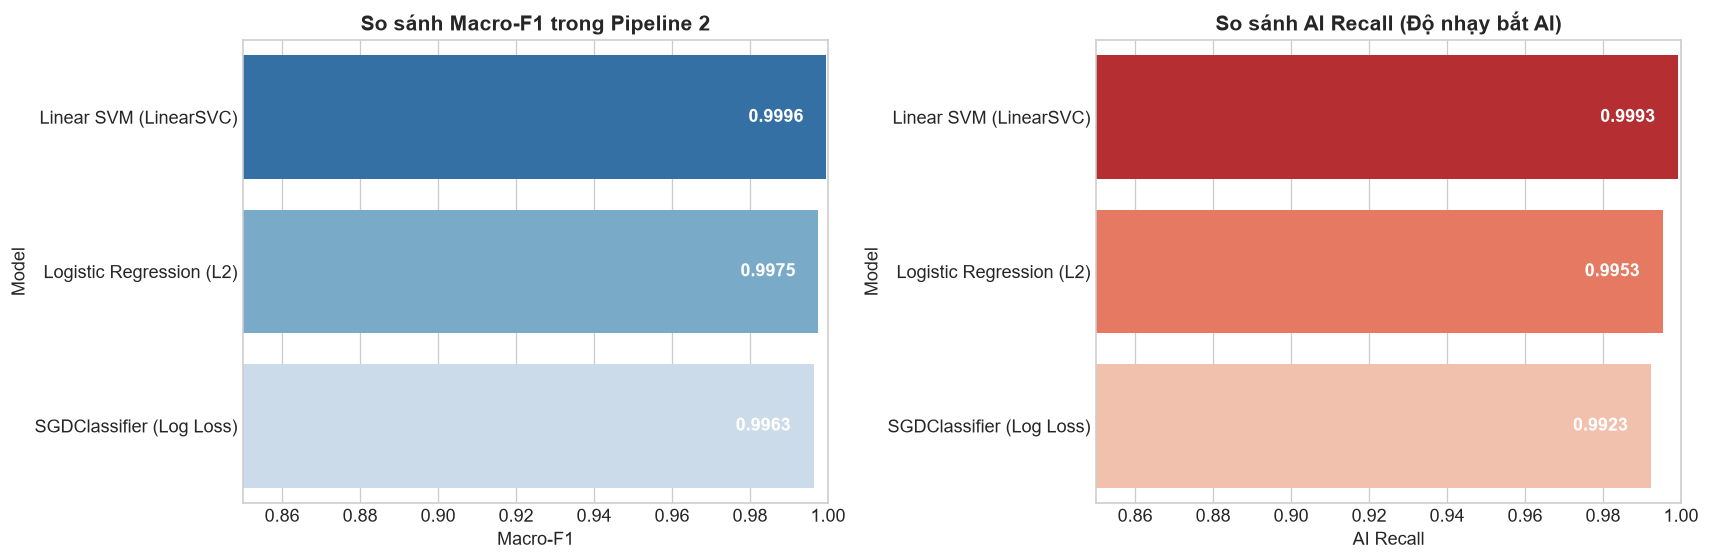

In [8]:
results_df = pd.DataFrame(benchmark_results).sort_values(by='Macro-F1', ascending=False).reset_index(drop=True)

print("🏆 BẢNG XẾP HẠNG CÁC MÔ HÌNH PIPELINE 2 (DUAL-CHANNEL TF-IDF):")
display(results_df.style.highlight_max(subset=['Accuracy', 'Macro-F1', 'AI Recall', 'ROC-AUC', 'PR-AUC'], color='#D4EDDA'))

# Đọc kết quả Pipeline 1 (nếu có) để đối chiếu
pipe1_metrics_path = Path("../models/pipeline1/pipeline1_metrics.json")
if not pipe1_metrics_path.exists():
    pipe1_metrics_path = Path("models/pipeline1/pipeline1_metrics.json")

if pipe1_metrics_path.exists():
    try:
        with open(pipe1_metrics_path, 'r', encoding='utf-8') as f:
            pipe1_data = json.load(f)
        pipe1_best = pipe1_data[0]
        pipe2_best = results_df.iloc[0]
        
        comparison = pd.DataFrame([
            {'Pipeline': 'Pipeline 1 (Chỉ Word TF-IDF)', 'Model': pipe1_best['Model'], 'Macro-F1': pipe1_best['Macro-F1'], 'AI Recall': pipe1_best['AI Recall'], 'AI Precision': pipe1_best['AI Precision']},
            {'Pipeline': 'Pipeline 2 (Word + Char TF-IDF)', 'Model': pipe2_best['Model'], 'Macro-F1': pipe2_best['Macro-F1'], 'AI Recall': pipe2_best['AI Recall'], 'AI Precision': pipe2_best['AI Precision']},
        ])
        print("\n🔥 SO SÁNH ĐỐI ĐẦU: PIPELINE 1 vs PIPELINE 2:")
        display(comparison)
    except Exception as e:
        print(f"ℹ️ Không đọc được file metrics Pipeline 1: {e}")

# Vẽ biểu đồ thanh so sánh
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(data=results_df, x='Macro-F1', y='Model', palette='Blues_r', ax=axes[0])
axes[0].set_title('So sánh Macro-F1 trong Pipeline 2', fontweight='bold')
axes[0].set_xlim(0.85, 1.0)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_width():.4f}", (p.get_width() - 0.02, p.get_y() + p.get_height() / 2),
                     color='white', fontweight='bold', va='center')

sns.barplot(data=results_df, x='AI Recall', y='Model', palette='Reds_r', ax=axes[1])
axes[1].set_title('So sánh AI Recall (Độ nhạy bắt AI)', fontweight='bold')
axes[1].set_xlim(0.85, 1.0)
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_width():.4f}", (p.get_width() - 0.02, p.get_y() + p.get_height() / 2),
                     color='white', fontweight='bold', va='center')

plt.tight_layout()
plt.show()


---
## 8. Ma Trận Nhầm Lẫn & Tinh chỉnh Ngưỡng Quyết định (Threshold Tuning)
Mặc định ngưỡng là $0.5$. Ta có thể tinh chỉnh ngưỡng xác suất trên Validation Set để tối ưu hóa **AI Recall** (bắt trúng nhiều AI nhất) hoặc **Macro-F1**.


🥇 Mô hình chiến thắng Pipeline 2: Linear SVM (LinearSVC)


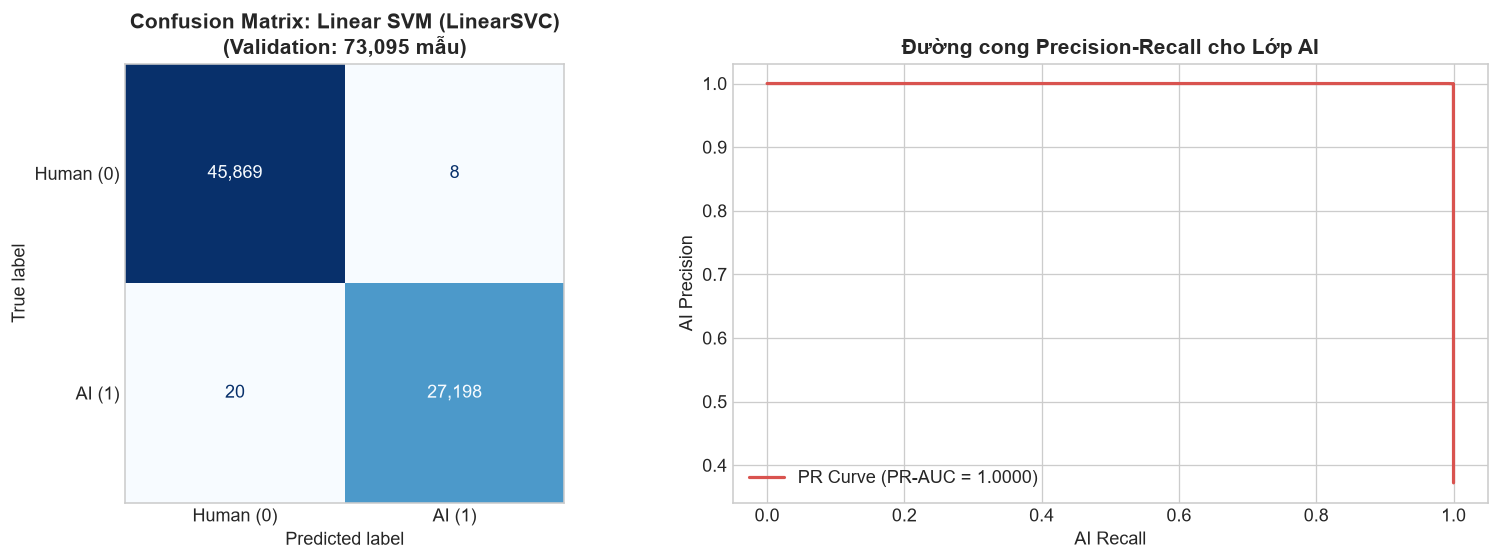

🎯 Ngưỡng quyết định tối ưu trên Validation: Threshold = 0.48 (Macro-F1 đạt 0.9996)


In [9]:
best_name = results_df.iloc[0]['Model']
best_model, best_pred, best_prob = trained_models[best_name]

print(f"🥇 Mô hình chiến thắng Pipeline 2: {best_name}")

cm = confusion_matrix(y_val, best_pred)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Confusion Matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Human (0)', 'AI (1)'])
disp.plot(cmap='Blues', values_format=',d', ax=axes[0], colorbar=False)
axes[0].set_title(f'Confusion Matrix: {best_name}\n(Validation: {len(y_val):,} mẫu)', fontweight='bold')
axes[0].grid(False)

# 2. Precision-Recall Curve
if best_prob is not None:
    prec_vals, rec_vals, thresholds = precision_recall_curve(y_val, best_prob)
    axes[1].plot(rec_vals, prec_vals, color='#D9534F', lw=2, label=f'PR Curve (PR-AUC = {results_df.iloc[0]["PR-AUC"]:.4f})')
    axes[1].set_title('Đường cong Precision-Recall cho Lớp AI', fontweight='bold')
    axes[1].set_xlabel('AI Recall')
    axes[1].set_ylabel('AI Precision')
    axes[1].legend()

plt.tight_layout()
plt.show()

# Phân tích tìm Threshold tối ưu cho Macro-F1
if best_prob is not None:
    candidate_thresholds = np.linspace(0.3, 0.7, 41)
    f1_scores = []
    for th in candidate_thresholds:
        preds_th = (best_prob >= th).astype(int)
        _, _, f1_th, _ = precision_recall_fscore_support(y_val, preds_th, average=None, labels=[0, 1])
        f1_scores.append((f1_th[0] + f1_th[1]) / 2.0)
        
    best_idx = np.argmax(f1_scores)
    best_th = candidate_thresholds[best_idx]
    best_th_f1 = f1_scores[best_idx]
    print(f"🎯 Ngưỡng quyết định tối ưu trên Validation: Threshold = {best_th:.2f} (Macro-F1 đạt {best_th_f1:.4f})")


---
## 9. Đóng Gói Mô Hình vào `models/pipeline2/` & Hàm Dự Đoán Thực Chiến
Lưu cả hai bộ Vectorizer (`word_vectorizer`, `char_vectorizer`), mô hình `best_model.joblib` và cấu hình ngưỡng dự đoán.


In [10]:
MODEL_SAVE_DIR = Path("../models/pipeline2")
if not MODEL_SAVE_DIR.exists():
    MODEL_SAVE_DIR = Path("models/pipeline2")
MODEL_SAVE_DIR.mkdir(parents=True, exist_ok=True)

# 1. Lưu 2 Vectorizer
word_vec_path = MODEL_SAVE_DIR / "word_vectorizer.joblib"
char_vec_path = MODEL_SAVE_DIR / "char_vectorizer.joblib"
joblib.dump(word_vectorizer, word_vec_path)
joblib.dump(char_vectorizer, char_vec_path)

# 2. Lưu Mô hình tốt nhất
model_save_path = MODEL_SAVE_DIR / "best_model.joblib"
joblib.dump(best_model, model_save_path)

# 3. Lưu bảng kết quả benchmark ra JSON
metrics_save_path = MODEL_SAVE_DIR / "pipeline2_metrics.json"
results_df.to_json(metrics_save_path, orient='records', indent=2)

print(f"💾 Đã lưu Word Vectorizer: {word_vec_path.resolve()}")
print(f"💾 Đã lưu Char Vectorizer: {char_vec_path.resolve()}")
print(f"💾 Đã lưu Model chiến thắng: {model_save_path.resolve()}")
print(f"💾 Đã lưu Kết quả Metrics:   {metrics_save_path.resolve()}")


💾 Đã lưu Word Vectorizer: D:\Project SamSung\AI-gen-text-detection\models\pipeline2\word_vectorizer.joblib
💾 Đã lưu Char Vectorizer: D:\Project SamSung\AI-gen-text-detection\models\pipeline2\char_vectorizer.joblib
💾 Đã lưu Model chiến thắng: D:\Project SamSung\AI-gen-text-detection\models\pipeline2\best_model.joblib
💾 Đã lưu Kết quả Metrics:   D:\Project SamSung\AI-gen-text-detection\models\pipeline2\pipeline2_metrics.json


In [11]:
# ==============================================================================
# HÀM MẪU SẴN SÀNG CHO CHROME EXTENSION BACKEND (FASTAPI)
# ==============================================================================
def predict_ai_generated_text(text: str, threshold: float = 0.5):
    """
    Hàm nhận vào 1 đoạn văn bản thô bất kỳ từ Chrome Extension,
    trả về nhãn dự đoán, xác suất AI (%) và thời gian xử lý (latency ms).
    """
    t_start = time.perf_counter()
    
    # 1. Biến đổi qua Kênh 1 (Word)
    w_feat = word_vectorizer.transform([text])
    
    # 2. Biến đổi qua Kênh 2 (Char)
    c_feat = char_vectorizer.transform([text])
    
    # 3. Ghép nối không gian
    feat_dual = hstack([w_feat, c_feat], format='csr')
    
    # 4. Dự đoán xác suất
    if hasattr(best_model, 'predict_proba'):
        prob_ai = best_model.predict_proba(feat_dual)[0, 1]
    else:
        score = best_model.decision_function(feat_dual)[0]
        prob_ai = 1.0 / (1.0 + np.exp(-score))
        
    is_ai = bool(prob_ai >= threshold)
    latency_ms = (time.perf_counter() - t_start) * 1000.0
    
    return {
        'prediction': 'AI' if is_ai else 'Human',
        'ai_probability': round(float(prob_ai) * 100, 2),
        'confidence': round(float(prob_ai if is_ai else 1.0 - prob_ai) * 100, 2),
        'latency_ms': round(latency_ms, 2)
    }


# Thử nghiệm hàm suy luận thực tế
test_samples = [
    "Cars have been around since they became famous in 1908. I think everyone should drive safely.",
    "Additionally, it is crucial to recognize that technology plays a significant role in developing essential skills."
]

print("🧪 THỬ NGHIỆM HÀM SUY LUẬN SẴN SÀNG CHO CHROME EXTENSION:")
print("=" * 70)
for sample in test_samples:
    res = predict_ai_generated_text(sample)
    print(f"Văn bản: '{sample[:65]}...'")
    print(f"-> Dự đoán: {res['prediction']} | Xác suất AI: {res['ai_probability']}% | Độ trễ: {res['latency_ms']} ms")
    print("-" * 70)

print("""
================================================================================
🎉 HOÀN TẤT HUẤN LUYỆN PIPELINE 2 (DUAL-CHANNEL WORD + CHARACTER TF-IDF)!
Ứng viên ưu tiên số 1 cho Chrome Extension đã sẵn sàng!
================================================================================
""")


🧪 THỬ NGHIỆM HÀM SUY LUẬN SẴN SÀNG CHO CHROME EXTENSION:
Văn bản: 'Cars have been around since they became famous in 1908. I think e...'
-> Dự đoán: Human | Xác suất AI: 48.85% | Độ trễ: 18.82 ms
----------------------------------------------------------------------
Văn bản: 'Additionally, it is crucial to recognize that technology plays a ...'
-> Dự đoán: AI | Xác suất AI: 97.11% | Độ trễ: 7.77 ms
----------------------------------------------------------------------

🎉 HOÀN TẤT HUẤN LUYỆN PIPELINE 2 (DUAL-CHANNEL WORD + CHARACTER TF-IDF)!
Ứng viên ưu tiên số 1 cho Chrome Extension đã sẵn sàng!

